<a href="https://colab.research.google.com/github/mariamhamdi917-stack/ML_projects/blob/main/bank_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:
df = pd.read_csv('/content/bank(Target column deposit).csv')

In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [ ]:
df.shape

(8912, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8722 non-null   object 
 3   education  8825 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8865 non-null   object 
 8   contact    8773 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8872 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8872.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.837804
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.308903
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [ ]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,poutcome,deposit
count,8905,8722,8825,8908,8899,8865,8773,8884,8912,8903
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,no,no,cellular,may,unknown,no
freq,2078,4967,4341,8762,4657,7689,6298,2265,6638,4673


In [ ]:
df.isnull().sum()

,0
age,0
job,7
marital,190
education,87
default,4
balance,13
housing,13
loan,47
contact,139
day,19


In [ ]:
df.duplicated().sum()

np.int64(0)

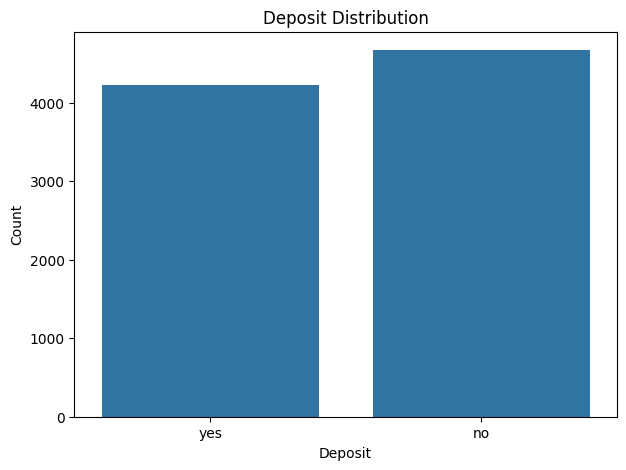

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='deposit')

plt.title('Deposit Distribution')
plt.xlabel('Deposit')
plt.ylabel('Count')

plt.show()

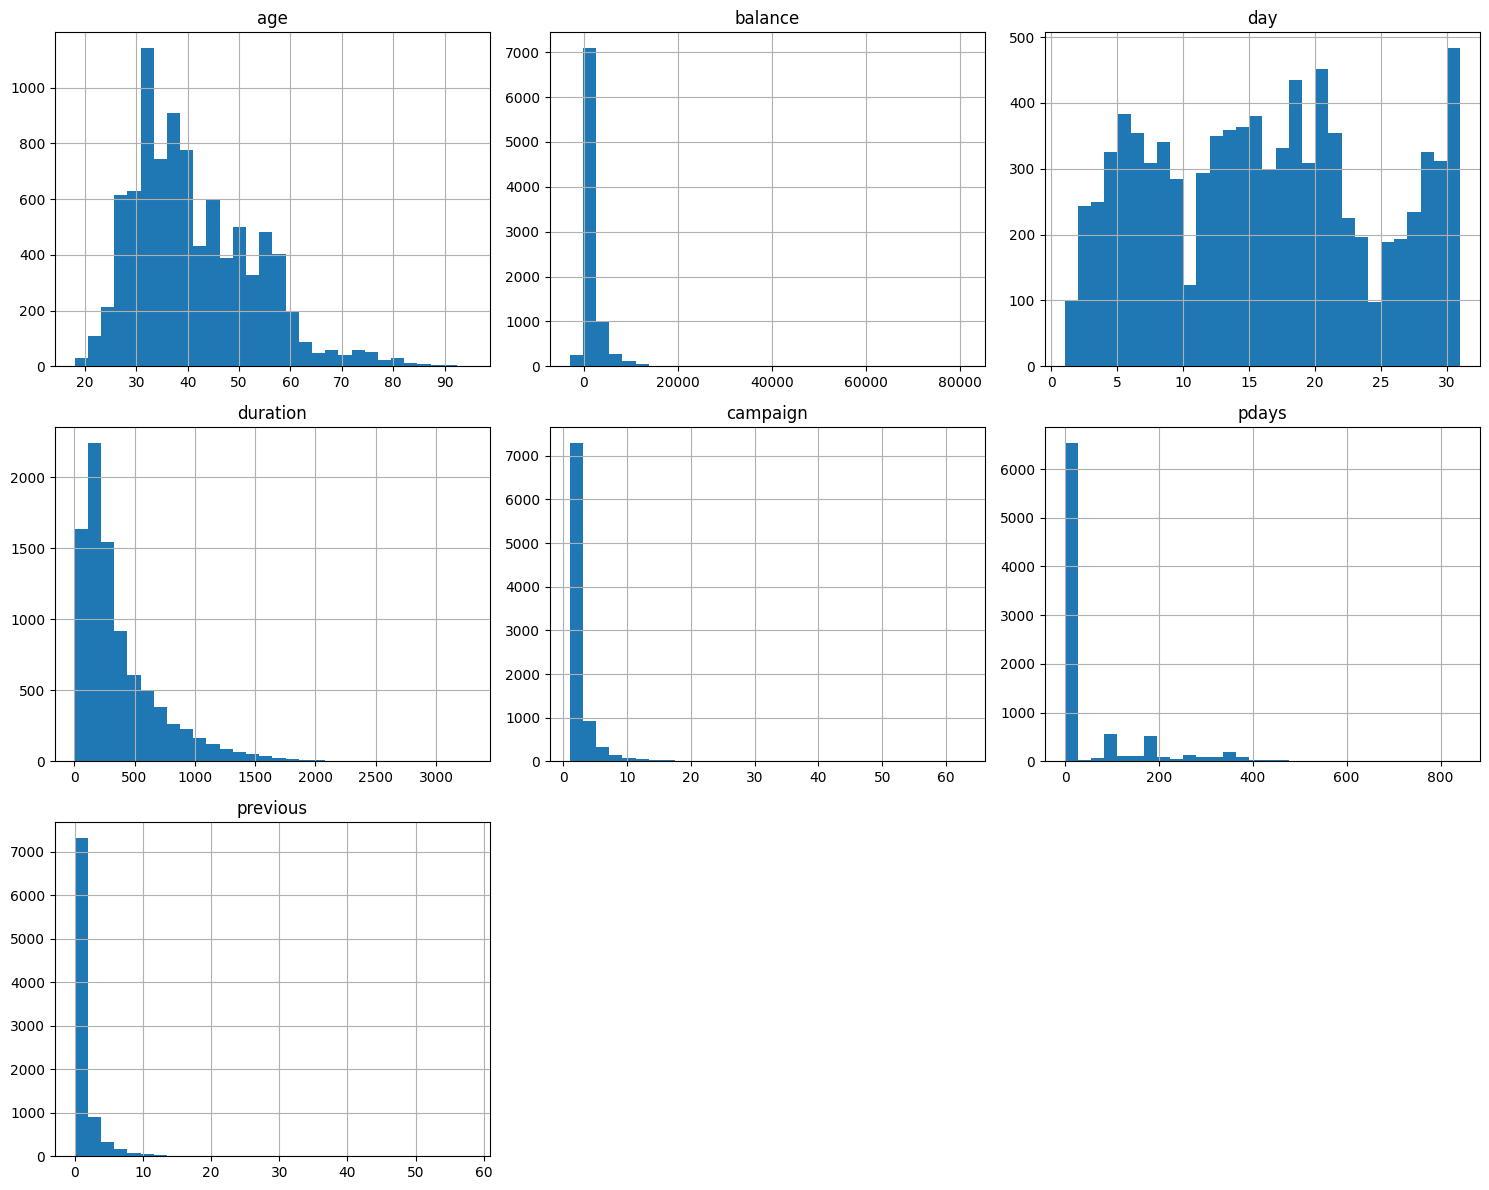

In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns

df[numerical_cols].hist(
    figsize=(15,12),
    bins=30
)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(15,10))

for i, col in enumerate(numerical_cols):
    plt.subplot(3,3,i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()
plt.show()

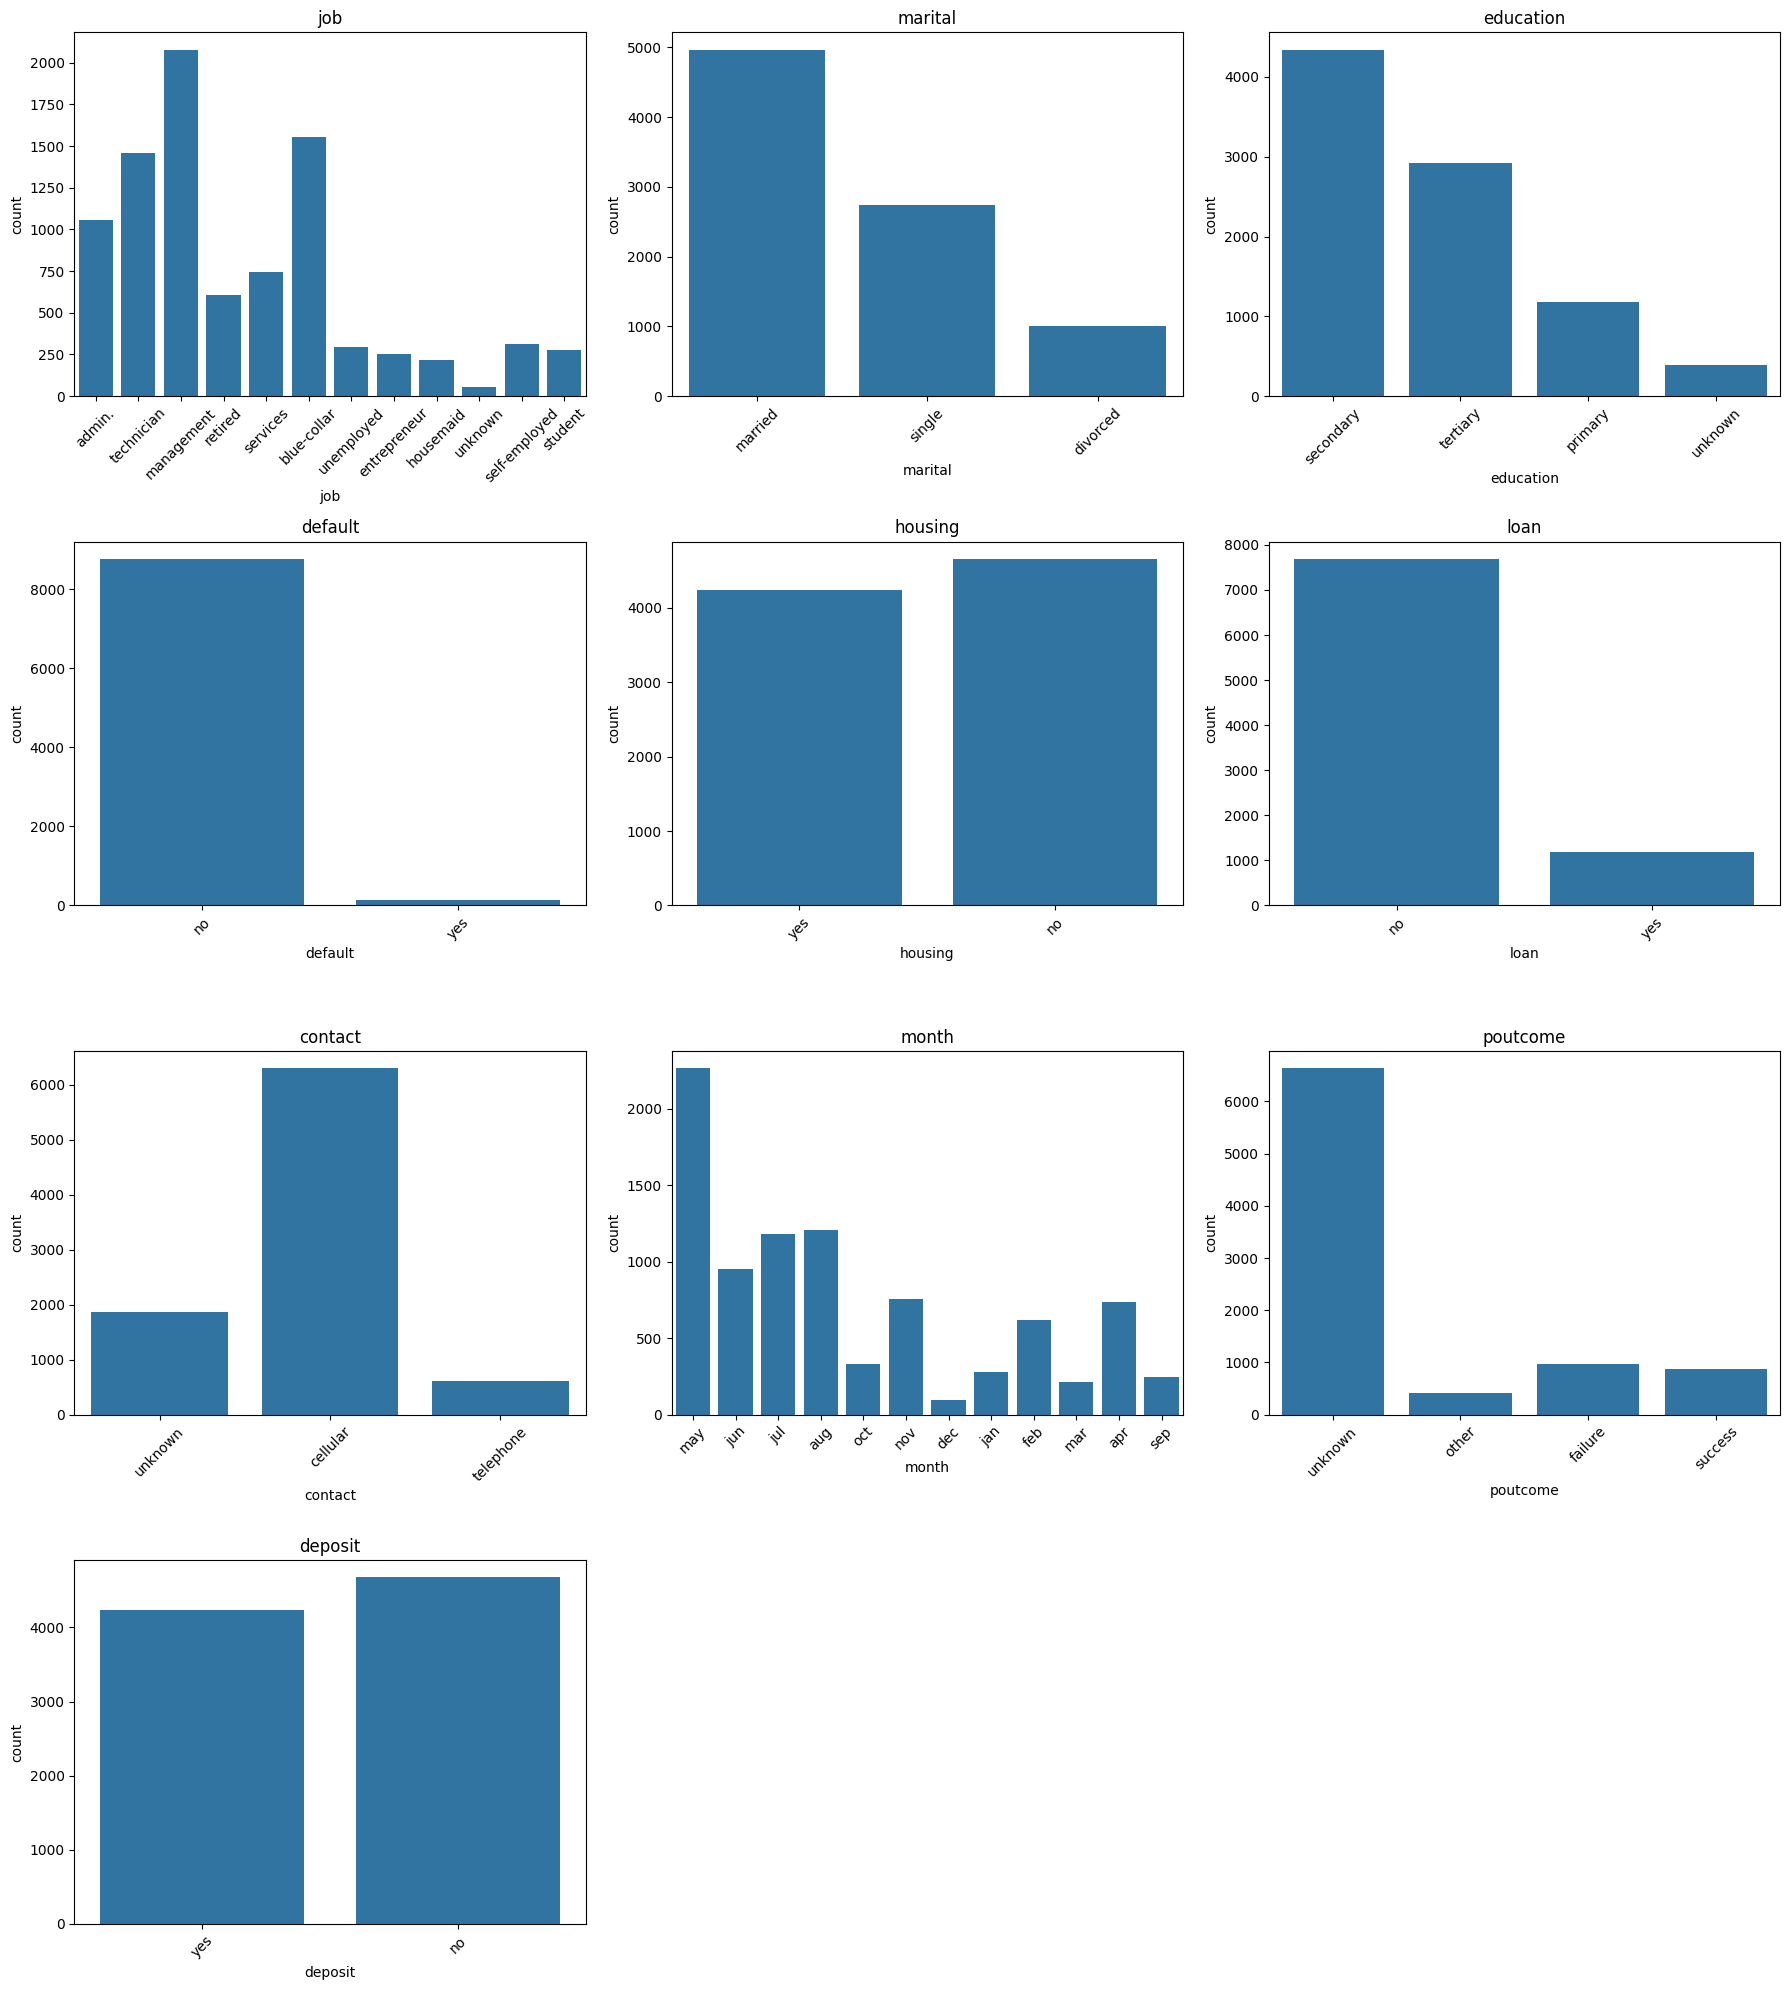

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns

plt.figure(figsize=(18,20))

for i, col in enumerate(categorical_cols):
    plt.subplot(4,3,i+1)

    sns.countplot(data=df, x=col)

    plt.title(col)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

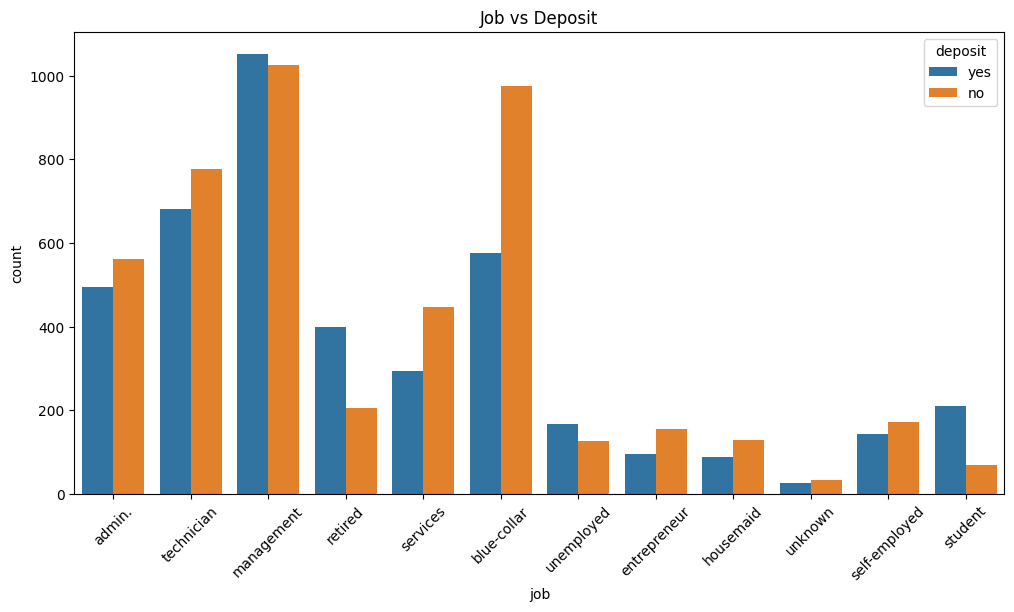

In [ ]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x='job',
    hue='deposit'
)

plt.title('Job vs Deposit')
plt.xticks(rotation=45)

plt.show()

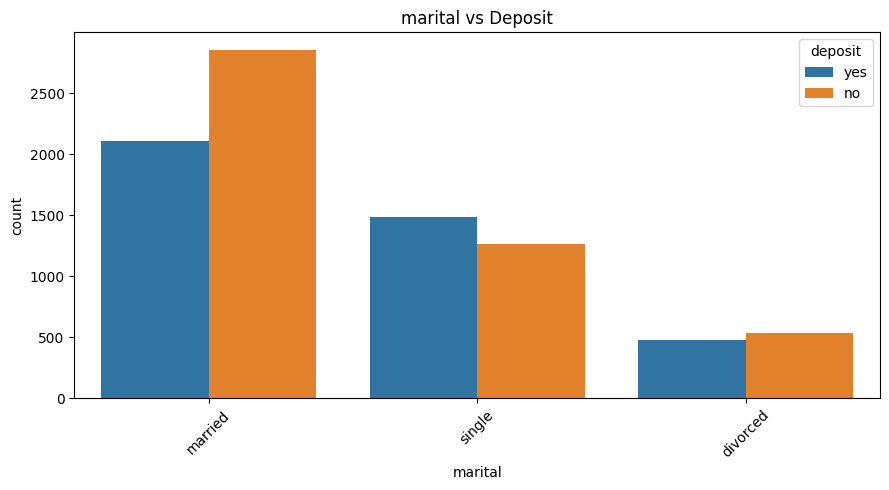

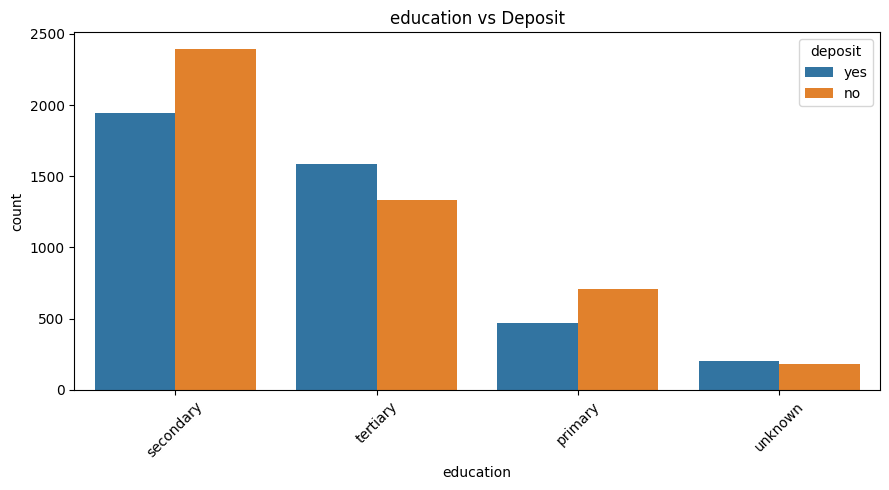

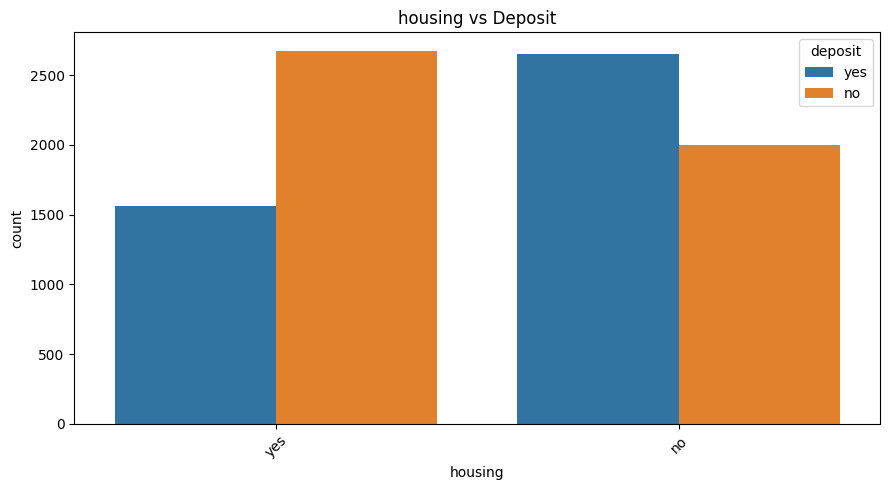

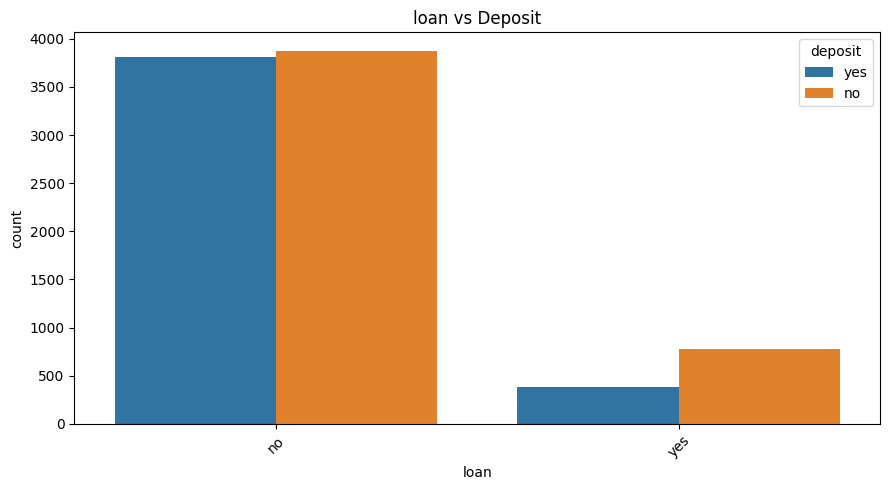

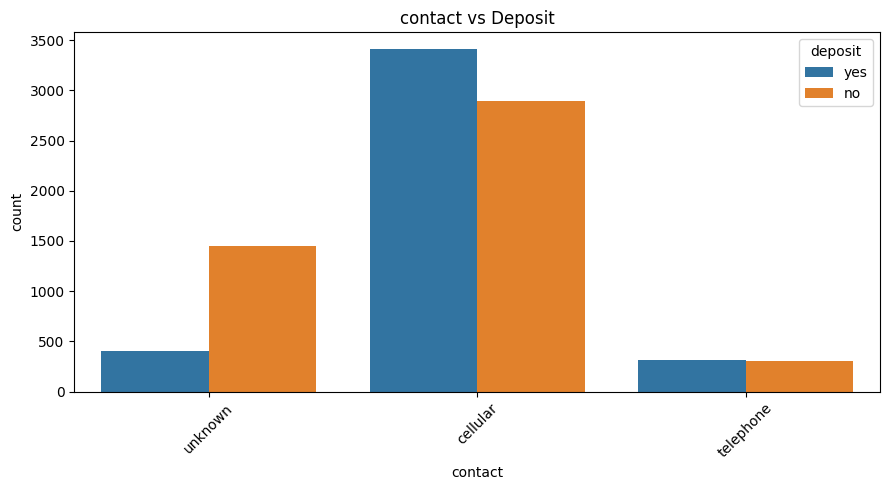

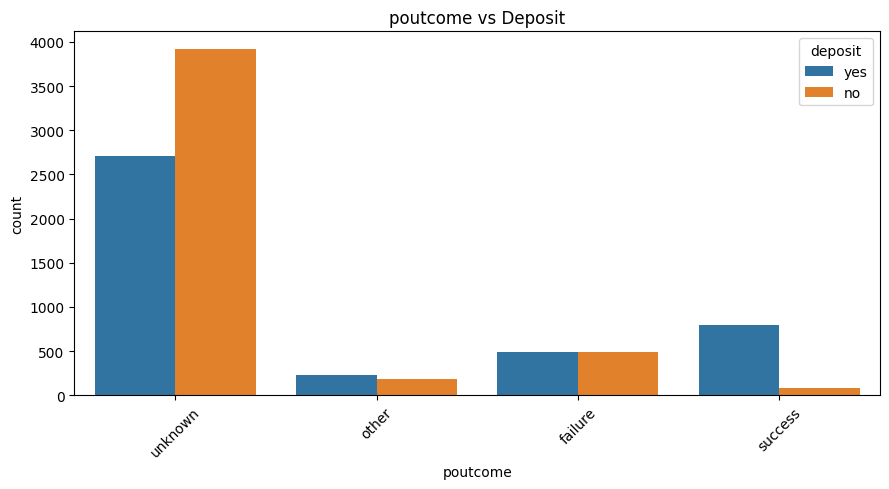

In [ ]:
features = ['marital', 'education', 'housing',
            'loan', 'contact', 'poutcome']

for col in features:

    plt.figure(figsize=(9,5))

    sns.countplot(
        data=df,
        x=col,
        hue='deposit'
    )

    plt.title(f'{col} vs Deposit')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [ ]:
# Remove rows with missing target
df = df.dropna(subset=['deposit'])

# Check
df['deposit'].isnull().sum()

np.int64(0)

In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(list(numerical_cols))

print("\nCategorical Columns:")
print(list(categorical_cols))

Numerical Columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical Columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']


In [ ]:
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

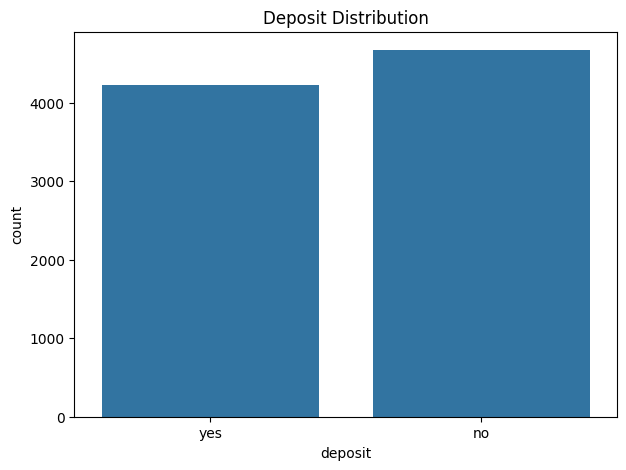

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='deposit')

plt.title('Deposit Distribution')
plt.show()

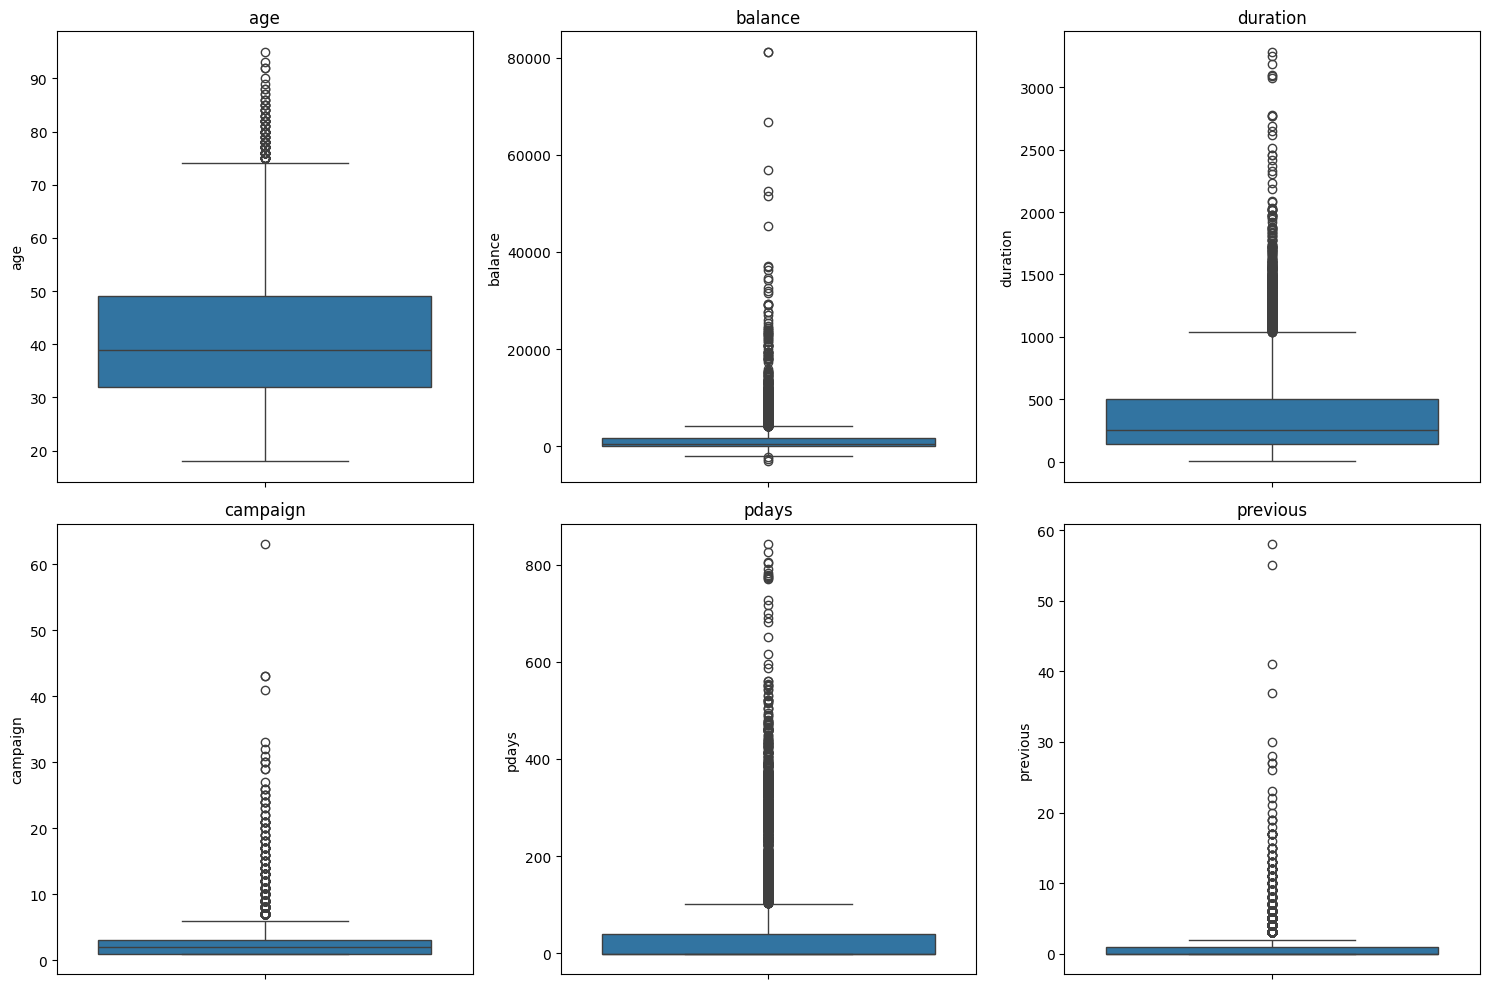

In [ ]:
outlier_cols = [
    'age', 'balance', 'duration',
    'campaign', 'pdays', 'previous'
]

plt.figure(figsize=(15,10))

for i, col in enumerate(outlier_cols):
    plt.subplot(2,3,i+1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
# Features
X = df.drop('deposit', axis=1)

# Target
y = df['deposit']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [ ]:
numerical_cols = X.select_dtypes(include=np.number).columns

categorical_cols = X.select_dtypes(include='object').columns

In [ ]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [ ]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [ ]:
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'KNN': KNeighborsClassifier(n_neighbors=5),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'SVM': SVC(kernel='rbf', C=1.0, gamma='scale'),

    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

In [ ]:
for name, model in models.items():

    model.fit(X_train_processed, y_train)

    print(name, "Trained Successfully")

Logistic Regression Trained Successfully
KNN Trained Successfully
Decision Tree Trained Successfully
Random Forest Trained Successfully
SVM Trained Successfully
Gradient Boosting Trained Successfully


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test_processed)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label='yes'),
        'Recall': recall_score(y_test, y_pred, pos_label='yes'),
        'F1 Score': f1_score(y_test, y_pred, pos_label='yes')
    })

results_df = pd.DataFrame(results)

results_df.sort_values(by='F1 Score', ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
3,Random Forest,0.850084,0.817783,0.880615,0.848036
4,SVM,0.846715,0.813115,0.879433,0.844974
5,Gradient Boosting,0.844469,0.818589,0.864066,0.840713
0,Logistic Regression,0.818080,0.815217,0.797872,0.806452
1,KNN,0.799551,0.809102,0.756501,0.781918
2,Decision Tree,0.788883,0.771991,0.788416,0.780117


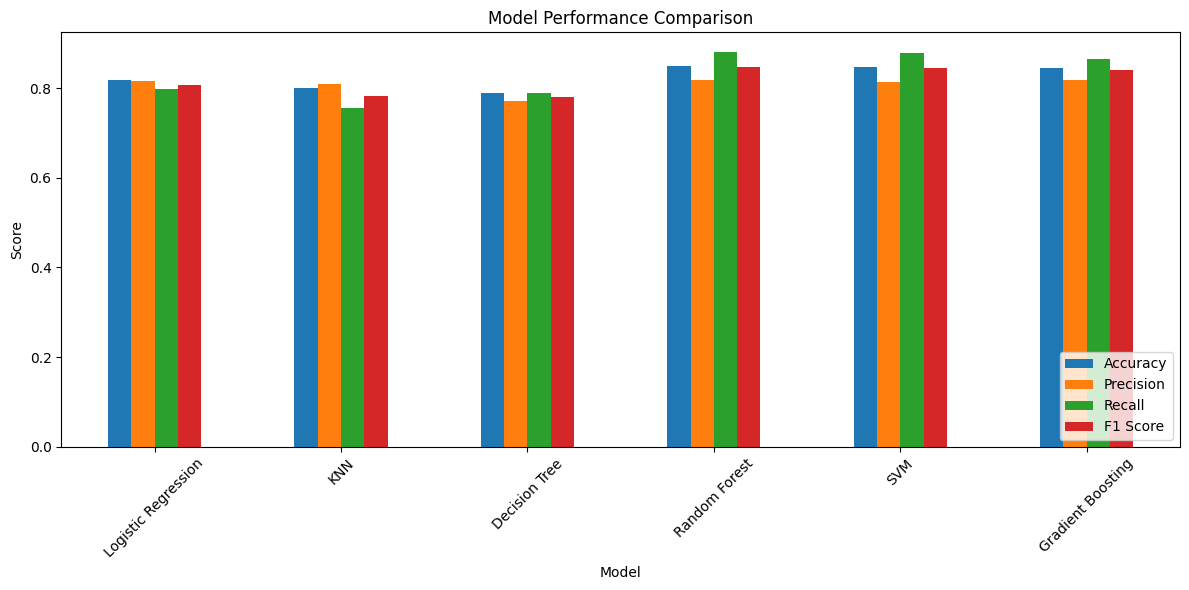

In [ ]:
results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

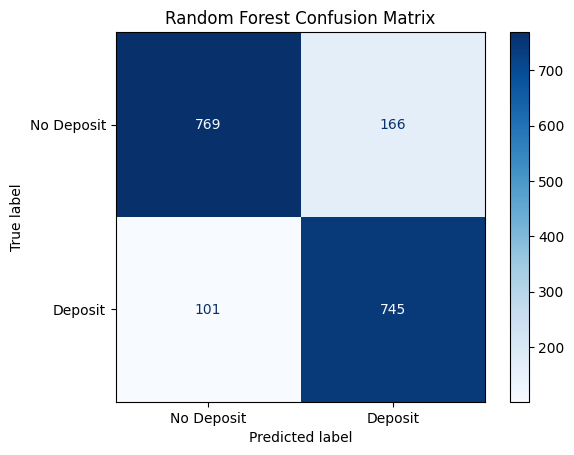

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model = models['Random Forest']

y_pred = best_model.predict(X_test_processed)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['no', 'yes']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Deposit', 'Deposit']
)

disp.plot(cmap='Blues')

plt.title('Random Forest Confusion Matrix')
plt.show()